In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv(r"C:\Users\Siddarood\Data Science 2\DS Morning 9th Feb 2026\DS Morning 9th Feb 2026\DB_dataset.csv")

In [3]:
df.shape

(500, 2)

In [4]:
df.head()

,Weight,Height
0,67.062924,176.086355
1,68.804094,178.388668
2,60.930863,170.284496
3,59.733843,168.691992
4,65.431230,173.763679


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

Weight    0
Height    0
dtype: int64

In [9]:
std_sca = StandardScaler()
features = pd.DataFrame(std_sca.fit_transform(df),columns=df.columns)
features.head()

,Weight,Height
0,1.115742,1.368788
1,1.451113,1.848408
2,-0.065368,0.160139
3,-0.295929,-0.171612
4,0.801458,0.884926


For finding the best eps(no_of clusters) value we have one best approach called nearestneighbour this will tell us if how much no of cluster we give the model will give best result.

In [12]:
from sklearn.neighbors import NearestNeighbors
n_neigh = NearestNeighbors(n_neighbors=10)
n_neigh.fit(features)

,n_neighbors,10
,radius,1.0
,algorithm,'auto'
,leaf_size,30
,metric,'minkowski'
,p,2
,metric_params,None
,n_jobs,None


In [13]:
distance, index= n_neigh.kneighbors(features)

In [14]:
distance[0]

array([0.        , 0.01507492, 0.0245175 , 0.0451716 , 0.04921661,
       0.05022186, 0.05572872, 0.05659828, 0.06039896, 0.06667069])

In [15]:
index[0]

array([  0, 353, 329, 119, 287, 274,  16, 221, 282,  59])

In [16]:
distance1=sorted(distance[:,1])

The distance1 contains the first closest pts for all the pts.

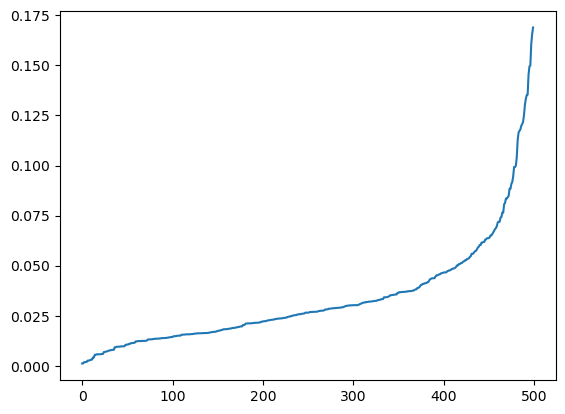

In [17]:
plt.plot(distance1)